In [3]:
%pip install pandas

   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.6 MB ? eta -:--:--
   ----- ---------------------------------- 1.3/9.6 MB 5.3 MB/s eta 0:00:02
   ------------- -------------------------- 3.1/9.6 MB 6.8 MB/s eta 0:00:01
   ------------------- -------------------- 4.7/9.6 MB 7.3 MB/s eta 0:00:01
   --------------------------- ------------ 6.6/9.6 MB 7.6 MB/s eta 0:00:01
   ------------------------------ --------- 7.3/9.6 MB 6.6 MB/s eta 0:00:01
   -------------------------------- ------- 7.9/9.6 MB 6.0 MB/s eta 0:00:01
   ---------------------------------- ----- 8.4/9.6 MB 5.5 MB/s eta 0:00:01
   ----------------------------------- ---- 8.7/9.6 MB 5.1 MB/s eta 0:00:01
   ------------------------------------ --- 8.9/9.6 MB 4.9 MB/s eta 0:00:01
   -------------------------------------- - 9.2/9.6 MB 4.5 MB/s eta 0:00:01
   ---------------------------------------- 9.6/9.6 MB 4.1 MB/s eta 0:00:00
   -----------------------


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd

df = pd.read_csv("db.csv")
print(df.head())

   gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No Info  27.32   
2    Male  28.0             0              0           never  27.32   
3  Female  36.0             0              0         current  23.45   
4    Male  76.0             1              1         current  20.14   

   HbA1c_level  blood_glucose_level  diabetes  
0          6.6                  140         0  
1          6.6                   80         0  
2          5.7                  158         0  
3          5.0                  155         0  
4          4.8                  155         0  


In [5]:
print(df.shape)
print(df.columns.tolist())
print(df.isnull().sum())

(100000, 9)
['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64


In [6]:
df.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [7]:
print("Dataset shape:", df.shape)
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Dataset shape: (100000, 9)
Missing values:
 gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64
Duplicate rows: 3854


In [8]:
# Remove duplicate rows
df = df.drop_duplicates()

# Fill missing numerical values with their column averages
numeric_cols = df.select_dtypes(include="number").columns
df[numeric_cols] = df[numeric_cols].fillna(
    df[numeric_cols].mean()
)

# Remove rows where text/category values are missing
df = df.dropna()

print("Remaining missing values:\n", df.isnull().sum())

Remaining missing values:
 gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64


In [9]:
print(df.columns.tolist())

['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']


In [12]:
df["AgeGroup"] = pd.cut(
    df["age"],
    bins=[0, 20, 30, 40, 50, 60, 100],
    labels=["0-20", "21-30", "31-40",
            "41-50", "51-60", "60+"]
)

print(df[["age", "AgeGroup"]].head())

    age AgeGroup
0  80.0      60+
1  54.0    51-60
2  28.0    21-30
3  36.0    31-40
4  76.0      60+


In [18]:
print(df.columns.tolist())

['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes', 'ageGroup', 'AgeGroup']


In [19]:
result = df.groupby(
    "AgeGroup",
    observed=True
)["blood_glucose_level"].mean()

print(result)

AgeGroup
0-20     133.056946
21-30    134.167377
31-40    134.359813
41-50    137.454900
51-60    141.100320
60+      145.818226
Name: blood_glucose_level, dtype: float64


In [20]:
%pip install seaborn

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ----------- ---------------------------- 2.6/9.3 MB 14.0 MB/s eta 0:00:01
   ------------------- -------------------- 4.5/9.3 MB 10.5 MB/s eta 0:00:01
   ------------------------ --------------- 5.8/9.3 MB 8.9 MB/s eta 0:00:01
   ---------------------------- ----------- 6.6/9.3 MB 7.8 MB/s eta 0:00:01
   ------------------------------ --------- 7.1/9.3 MB 7.1 MB/s eta 0:00:01
   -------------------------------- ------- 7.6/9.3 MB 6.3 MB/s eta 0:00:01
   ---------------------------------- ----- 8.1/9.3 MB 5.5 MB/s eta 0:00:01
   ------------------------------------- -- 8.7/9.3 MB 5.1 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 4.9 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 4.7 MB/s eta 0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


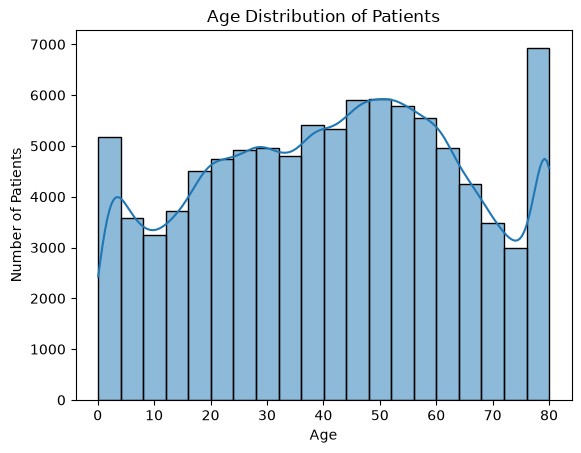

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(df["age"].dropna(), bins=20, kde=True)

plt.title("Age Distribution of Patients")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.show()

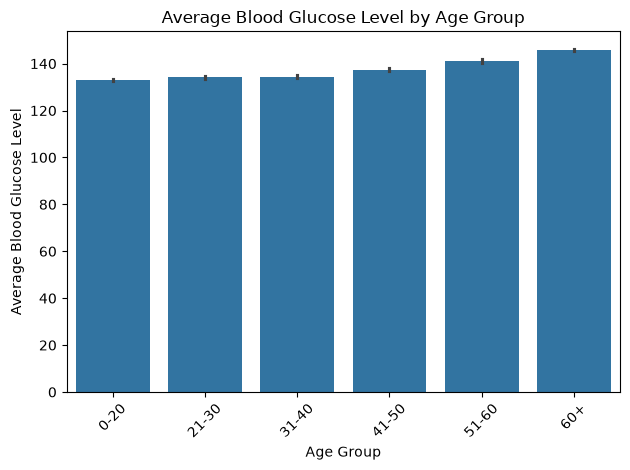

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.barplot(
    data=df,
    x="AgeGroup",
    y="blood_glucose_level"
)

plt.title("Average Blood Glucose Level by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Blood Glucose Level")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

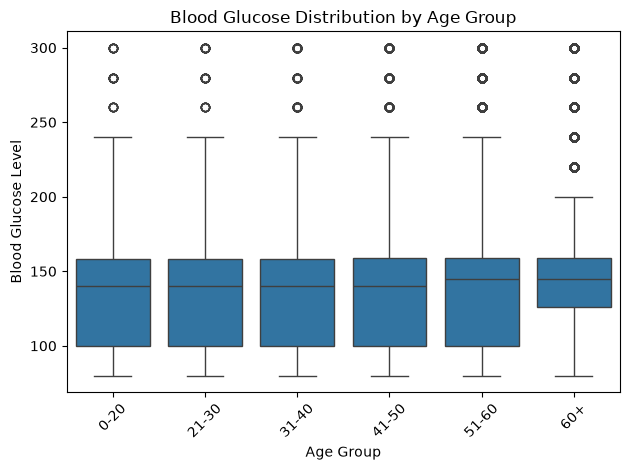

In [24]:
sns.boxplot(
    data=df,
    x="AgeGroup",
    y="blood_glucose_level"
)

plt.title("Blood Glucose Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Blood Glucose Level")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

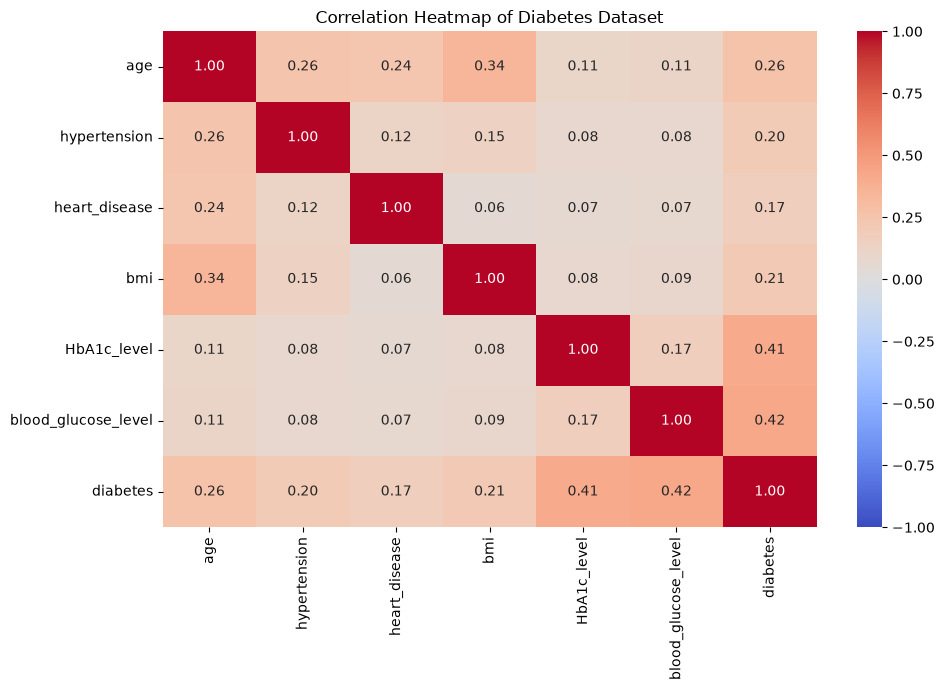

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Calculate correlations
corr = numeric_df.corr()

# Create heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Diabetes Dataset")
plt.tight_layout()
plt.show()

In [26]:
print("HbA1c vs Diabetes:",
      df["HbA1c_level"].corr(df["diabetes"]))

print("Blood Glucose vs Diabetes:",
      df["blood_glucose_level"].corr(df["diabetes"]))

print("BMI vs Diabetes:",
      df["bmi"].corr(df["diabetes"]))

HbA1c vs Diabetes: 0.4064083758294862
Blood Glucose vs Diabetes: 0.4243358355790675
BMI vs Diabetes: 0.2149316999588767


In [27]:
summary = df.groupby("diabetes")[
    ["age", "bmi", "HbA1c_level", "blood_glucose_level"]
].mean()

print(summary)

                age        bmi  HbA1c_level  blood_glucose_level
diabetes                                                        
0         39.943229  26.869003     5.396936           132.818489
1         60.925961  31.997755     6.934827           194.026173


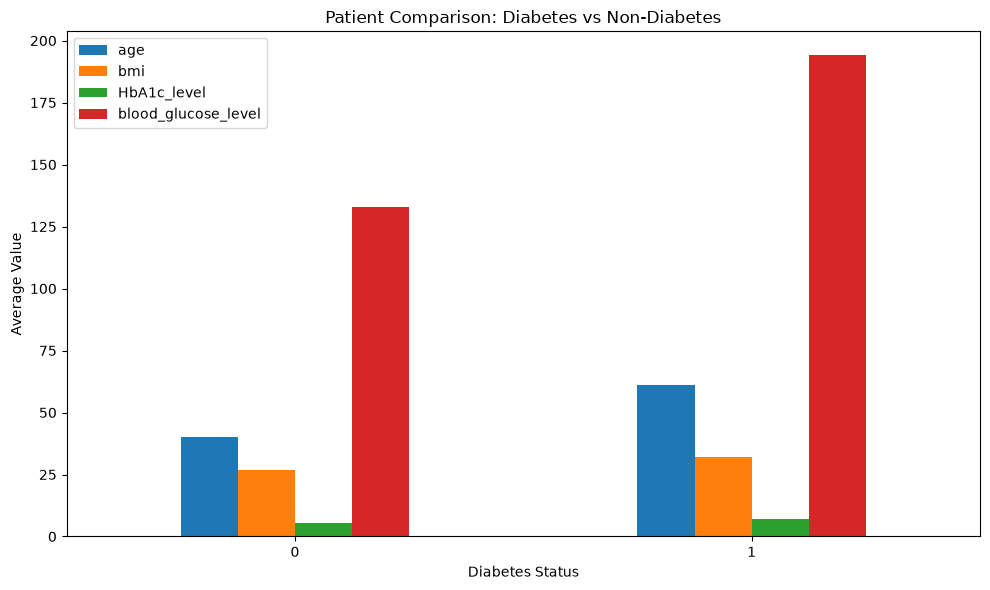

In [28]:
summary.plot(kind="bar", figsize=(10, 6))

plt.title("Patient Comparison: Diabetes vs Non-Diabetes")
plt.xlabel("Diabetes Status")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [5]:
import os

print("Current folder:", os.getcwd())
print("Files in this folder:", os.listdir())

Current folder: c:\Users\srash_f9aayz0\Desktop
Files in this folder: ['A7104425039- SRASHTI SRIVASTAVA.docx', 'average_age_positive.csv', 'Biopython', 'Bluebook.lnk', 'Canva.lnk', 'db.csv', 'desktop.ini', 'diabetes_analysis.ipynb', 'Documents', 'GitHub Desktop.lnk', 'healthcare-risk-data-analysis', 'healthcare_db.db', 'HVCO Portfolio.docx', 'Integrated assignment final.docx', 'NOC -Ms.Srashti Srivastava copy.docx', 'PYTHON', 'queries.csv', 'Saksham (Work) - Chrome.lnk', 'the.txt', 'this.txt', '~$final ppt for HVCO viva.pptx', '~$jftffffffffffffffffffffff.pptx']


In [7]:
import os

print("File size:", os.path.getsize("db.csv"), "bytes")

with open("db.csv", "rb") as f:
    print("First 30 bytes:", f.read(30))

File size: 8192 bytes
First 30 bytes: b'SQLite format 3\x00\x10\x00\x01\x01\x00@  \x00\x00\x00\x04\x00\x00'


In [8]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("db.csv")

tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table'",
    conn
)

print(tables)

Empty DataFrame
Columns: [name]
Index: []


In [9]:
conn = sqlite3.connect("healthcare_db.db")

tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table'",
    conn
)

print(tables)

Empty DataFrame
Columns: [name]
Index: []


In [10]:
import pandas as pd
import os

print("queries.csv exists:", os.path.exists("queries.csv"))
print("average_age_positive.csv exists:", os.path.exists("average_age_positive.csv"))

print("\n--- queries.csv ---")
print(pd.read_csv("queries.csv").head())

print("\n--- average_age_positive.csv ---")
print(pd.read_csv("average_age_positive.csv").head())

queries.csv exists: True
average_age_positive.csv exists: True

--- queries.csv ---
                                      -- Query 2: Maximum BMI by gender
SELECT gender                                   MAX(bmi) AS maximum_bmi
FROM patients                                                       NaN
GROUP BY gender;                                                    NaN
-- Query 4: Patients aged 40 or above                               NaN
SELECT *                                                            NaN

--- average_age_positive.csv ---
      SELECT gender   MAX(bmi) AS maximum_bmi
0     FROM patients                       NaN
1  GROUP BY gender;                       NaN


In [19]:
import pandas as pd

df = pd.read_csv("diabetes.csv")

print(df.head())
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

   gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No Info  27.32   
2    Male  28.0             0              0           never  27.32   
3  Female  36.0             0              0         current  23.45   
4    Male  76.0             1              1         current  20.14   

   HbA1c_level  blood_glucose_level  diabetes  
0          6.6                  140         0  
1          6.6                   80         0  
2          5.7                  158         0  
3          5.0                  155         0  
4          4.8                  155         0  
Dataset shape: (100000, 9)
Columns: ['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']


In [20]:

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check diabetes distribution
print("\nDiabetes distribution:")
print(df["diabetes"].value_counts())

# Check data types
print("\nData types:")
print(df.dtypes)


Missing values:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

Duplicate rows: 3854

Diabetes distribution:
diabetes
0    91500
1     8500
Name: count, dtype: int64

Data types:
gender                     str
age                    float64
hypertension             int64
heart_disease            int64
smoking_history            str
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object


In [21]:

# Make a copy of the original dataset
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Check the dataset after cleaning
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

# Check missing values again
print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

# Check categorical values
print("\nGender values:")
print(df_clean["gender"].value_counts())

print("\nSmoking history values:")
print(df_clean["smoking_history"].value_counts())


Original dataset shape: (100000, 9)
Cleaned dataset shape: (96146, 9)

Missing values after cleaning:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

Gender values:
gender
Female    56161
Male      39967
Other        18
Name: count, dtype: int64

Smoking history values:
smoking_history
never          34398
No Info        32887
former          9299
current         9197
not current     6367
ever            3998
Name: count, dtype: int64


In [22]:

# Summary statistics of numerical columns
print("Statistical Summary:")
display(df_clean.describe())

# Count people with and without diabetes
print("\nDiabetes Distribution:")
print(df_clean["diabetes"].value_counts())

# Percentage of each diabetes category
print("\nDiabetes Percentage:")
print(
    (df_clean["diabetes"].value_counts(normalize=True) * 100)
    .round(2)
)

# Average age for each diabetes category
print("\nAverage Age:")
print(df_clean.groupby("diabetes")["age"].mean())

# Average BMI for each diabetes category
print("\nAverage BMI:")
print(df_clean.groupby("diabetes")["bmi"].mean())


Statistical Summary:


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,96146.000000,96146.000000,96146.000000,96146.000000,96146.000000,96146.000000,96146.000000
mean,41.794326,0.077601,0.040803,27.321461,5.532609,138.218231,0.088220
std,22.462948,0.267544,0.197833,6.767716,1.073232,40.909771,0.283616
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.000000,0.000000,23.400000,4.800000,100.000000,0.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,59.000000,0.000000,0.000000,29.860000,6.200000,159.000000,0.000000
max,80.000000,1.000000,1.000000,95.690000,9.000000,300.000000,1.000000



Diabetes Distribution:
diabetes
0    87664
1     8482
Name: count, dtype: int64

Diabetes Percentage:
diabetes
0    91.18
1     8.82
Name: proportion, dtype: float64

Average Age:
diabetes
0    39.943229
1    60.925961
Name: age, dtype: float64

Average BMI:
diabetes
0    26.869003
1    31.997755
Name: bmi, dtype: float64


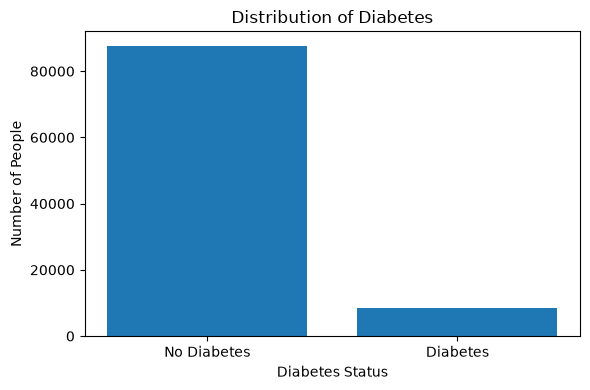

In [23]:

import matplotlib.pyplot as plt

# Count people with and without diabetes
diabetes_counts = df_clean["diabetes"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(
    ["No Diabetes", "Diabetes"],
    diabetes_counts.values
)

plt.title("Distribution of Diabetes")
plt.xlabel("Diabetes Status")
plt.ylabel("Number of People")
plt.tight_layout()
plt.show()


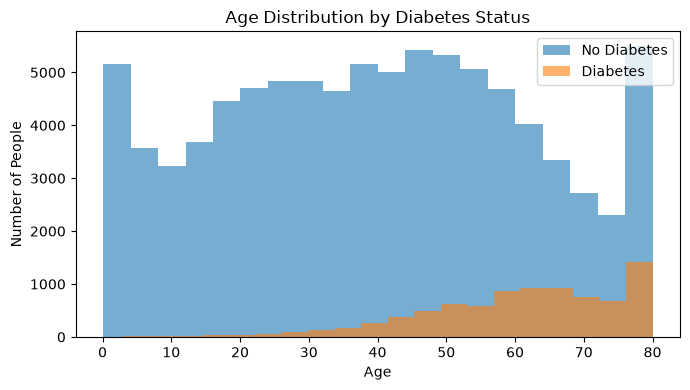

In [24]:

plt.figure(figsize=(7, 4))

plt.hist(
    df_clean.loc[df_clean["diabetes"] == 0, "age"],
    bins=20,
    alpha=0.6,
    label="No Diabetes"
)

plt.hist(
    df_clean.loc[df_clean["diabetes"] == 1, "age"],
    bins=20,
    alpha=0.6,
    label="Diabetes"
)

plt.title("Age Distribution by Diabetes Status")
plt.xlabel("Age")
plt.ylabel("Number of People")
plt.legend()
plt.tight_layout()
plt.show()


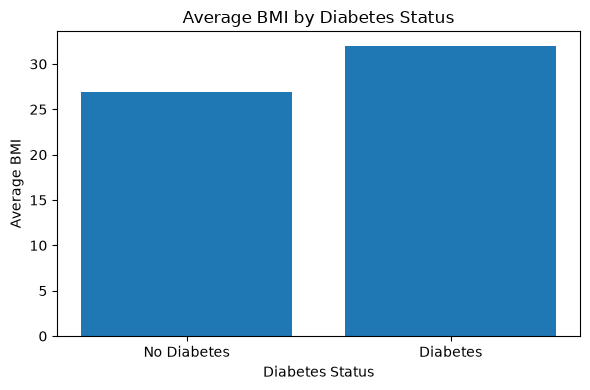

In [25]:

bmi_avg = df_clean.groupby("diabetes")["bmi"].mean()

plt.figure(figsize=(6, 4))
plt.bar(
    ["No Diabetes", "Diabetes"],
    [bmi_avg.loc[0], bmi_avg.loc[1]]
)

plt.title("Average BMI by Diabetes Status")
plt.xlabel("Diabetes Status")
plt.ylabel("Average BMI")
plt.tight_layout()
plt.show()


In [26]:

import pandas as pd

# Separate input features (X) and target (y)
X = df_clean.drop("diabetes", axis=1)
y = df_clean["diabetes"]

# Convert categorical columns into numerical columns
X = pd.get_dummies(
    X,
    columns=["gender", "smoking_history"],
    drop_first=True,
    dtype=int
)

# Display the processed data
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nEncoded feature columns:")
print(X.columns.tolist())

display(X.head())


Features shape: (96146, 13)
Target shape: (96146,)

Encoded feature columns:
['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'gender_Male', 'gender_Other', 'smoking_history_current', 'smoking_history_ever', 'smoking_history_former', 'smoking_history_never', 'smoking_history_not current']


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Male,gender_Other,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
0,80.0,0,1,25.19,6.6,140,0,0,0,0,0,1,0
1,54.0,0,0,27.32,6.6,80,0,0,0,0,0,0,0
2,28.0,0,0,27.32,5.7,158,1,0,0,0,0,1,0
3,36.0,0,0,23.45,5.0,155,0,0,1,0,0,0,0
4,76.0,1,1,20.14,4.8,155,1,0,1,0,0,0,0


In [28]:

%pip install scikit-learn


   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   ------- -------------------------------- 1.6/8.2 MB 11.9 MB/s eta 0:00:01
   ------------------- -------------------- 3.9/8.2 MB 14.9 MB/s eta 0:00:01
   -------------------------- ------------- 5.5/8.2 MB 10.4 MB/s eta 0:00:01
   ------------------------------- -------- 6.6/8.2 MB 8.7 MB/s eta 0:00:01
   ----------------------------------- ---- 7.3/8.2 MB 7.5 MB/s eta 0:00:01
   ---------------------------------------- 8.2/8.2 MB 7.3 MB/s eta 0:00:00
   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
    --------------------------------------- 0.5/36.6 MB 2.5 MB/s eta 0:00:15
   - -------------------------------------- 1.0/36.6 MB 2.5 MB/s eta 0:00:14
   - -------------------------------------- 1.6/36.6 MB 2.4 MB/s eta 0:00:15
   -- ------------------------------------- 2.1/36.6 MB 2.4 MB/s eta 0:00:15
   -- ------------------------------------- 2.6/36.6 MB 2.4 MB/s eta 0:00:14
   --- ----------


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [29]:

from sklearn.model_selection import train_test_split

print("Scikit-learn installed successfully!")


Scikit-learn installed successfully!


In [30]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (76916, 13)
Testing features: (19230, 13)
Training target: (76916,)
Testing target: (19230,)


In [31]:

from sklearn.linear_model import LogisticRegression

# Create the model
model = LogisticRegression(max_iter=1000)

# Train the model using training data
model.fit(X_train, y_train)

print("Model trained successfully!")


Model trained successfully!


In [32]:

# Predict diabetes status for test data
y_pred = model.predict(X_test)

print("First 10 actual values:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted values:")
print(y_pred[:10].tolist())


First 10 actual values:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

First 10 predicted values:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


Model Accuracy: 95.96%

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     17534
           1       0.87      0.64      0.74      1696

    accuracy                           0.96     19230
   macro avg       0.92      0.81      0.86     19230
weighted avg       0.96      0.96      0.96     19230



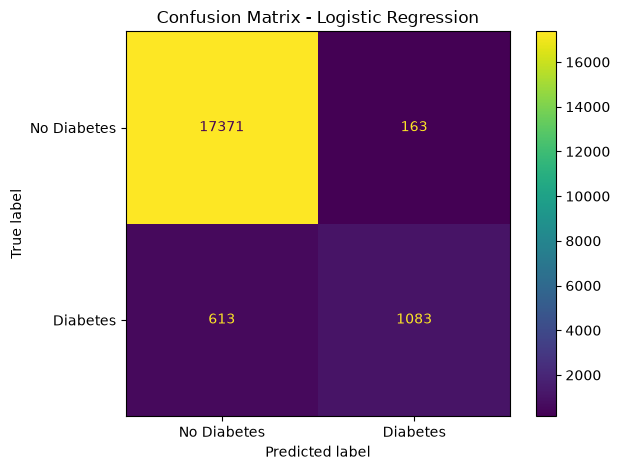

In [33]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

# Detailed performance report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Diabetes", "Diabetes"]
)

display_cm.plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()


In [34]:

print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Accuracy: 95.96 %

Confusion Matrix:
[[17371   163]
 [  613  1083]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     17534
           1       0.87      0.64      0.74      1696

    accuracy                           0.96     19230
   macro avg       0.92      0.81      0.86     19230
weighted avg       0.96      0.96      0.96     19230



In [35]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# Train a model that gives more weight to the minority class
model_balanced = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

model_balanced.fit(X_train, y_train)

# Make predictions
y_pred_balanced = model_balanced.predict(X_test)

# Evaluate the new model
print("Balanced Model Results")
print(classification_report(
    y_test,
    y_pred_balanced,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_balanced))


Balanced Model Results
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230

Confusion Matrix:
[[15519  2015]
 [  204  1492]]


In [36]:

from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score
import pandas as pd

comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Logistic Regression": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0)
    ],
    "Balanced Logistic Regression": [
        accuracy_score(y_test, y_pred_balanced),
        precision_score(y_test, y_pred_balanced, zero_division=0),
        recall_score(y_test, y_pred_balanced, zero_division=0),
        f1_score(y_test, y_pred_balanced, zero_division=0)
    ]
})

display(comparison.round(3))


,Metric,Logistic Regression,Balanced Logistic Regression
0,Accuracy,0.960,0.885
1,Precision,0.869,0.425
2,Recall,0.639,0.880
3,F1-score,0.736,0.574


### Model Comparison and Findings

Two Logistic Regression models were evaluated for diabetes prediction.

- The standard Logistic Regression model achieved 96.0% accuracy, 86.9% precision, and 63.9% recall.
- The Balanced Logistic Regression model achieved 88.5% accuracy, 42.5% precision, and 88.0% recall.
- The standard model performed better in accuracy and F1-score.
- The balanced model detected a greater proportion of actual diabetes cases, but generated more false-positive predictions.

**Conclusion:** The results demonstrate a trade-off between overall accuracy and detecting positive cases. Further testing and model improvement are needed before either model could be considered for real-world healthcare use.